# Demanda: índice de rotatividade de estoque

Série anual. Um LSTM com uma defasagem (`look_back = 1`) prevê o próximo ano
a partir do anterior. A divisão é cronológica: os primeiros 80% treinam,
o final testa. Embaralhar a série vazaria o futuro.

`batch_size = 1` atualiza o peso a cada ano e deixa a GPU ociosa.
Aqui o lote é 32 (ou o tamanho do treino, se for menor) e o TensorFlow usa
a GPU quando ela aparece. A série é curta: o tempo total continua baixo.
O número do RMSE pode mudar em relação ao lote 1.

In [1]:
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("GPU:", gpus or "nenhuma, treino na CPU")

GPU: nenhuma, treino na CPU


In [2]:
def janelas(serie, look_back):
    x = np.array([serie[i : i + look_back, 0] for i in range(len(serie) - look_back)])
    y = serie[look_back:, 0]
    return x.reshape(-1, look_back, 1), y


df = pd.read_csv("dataset.csv")
serie = df["indice_rotatividade_estoque"].to_numpy().reshape(-1, 1)
corte = int(len(serie) * 0.8)
treino, teste = serie[:corte], serie[corte:]

scaler = MinMaxScaler()
treino_n = scaler.fit_transform(treino)
teste_n = scaler.transform(teste)

LOOK_BACK = 1
X_treino, y_treino = janelas(treino_n, LOOK_BACK)
X_teste, y_teste = janelas(teste_n, LOOK_BACK)
print(X_treino.shape, X_teste.shape)

modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(LOOK_BACK, 1)),
    tf.keras.layers.LSTM(50),
    tf.keras.layers.Dense(1),
])
modelo.compile(optimizer="adam", loss="mean_squared_error")
modelo.fit(
    X_treino,
    y_treino,
    epochs=50,
    batch_size=min(32, len(X_treino)),
    verbose=0,
)

def rmse(y, previsto):
    y_real = scaler.inverse_transform(y.reshape(-1, 1))[:, 0]
    y_hat = scaler.inverse_transform(previsto)[:, 0]
    return y_real, y_hat, np.sqrt(mean_squared_error(y_real, y_hat))


y_tr, hat_tr, rmse_tr = rmse(y_treino, modelo.predict(X_treino, verbose=0))
y_te, hat_te, rmse_te = rmse(y_teste, modelo.predict(X_teste, verbose=0))
print("RMSE treino %.2f  teste %.2f" % (rmse_tr, rmse_te))

(43, 1, 1) (10, 1, 1)
RMSE treino 1.43  teste 0.82


O primeiro ano de cada fatia não tem previsão: ele é a janela, não o alvo.
Por isso o índice do teste começa duas posições depois do fim do treino
(`look_back` no treino e outro no teste).

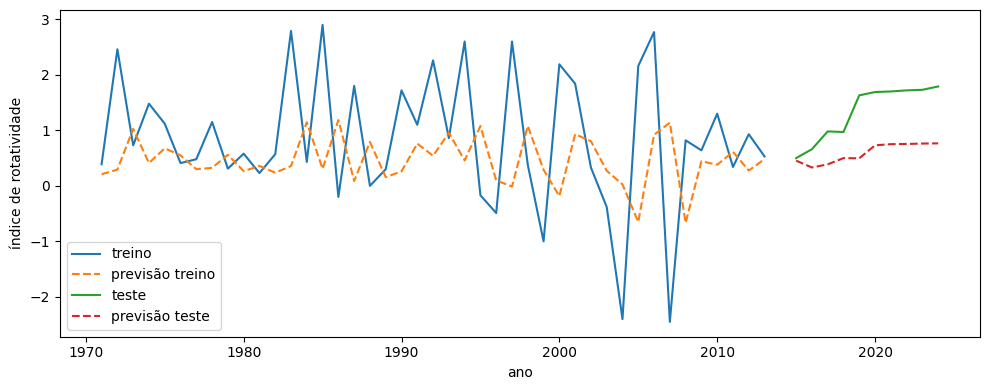

In [3]:
anos = df["ano"]
i_tr = anos.iloc[LOOK_BACK : LOOK_BACK + len(y_tr)]
i_te = anos.iloc[len(y_tr) + 2 * LOOK_BACK : len(y_tr) + 2 * LOOK_BACK + len(y_te)]

plt.figure(figsize=(10, 4))
plt.plot(i_tr, y_tr, label="treino")
plt.plot(i_tr, hat_tr, "--", label="previsão treino")
plt.plot(i_te, y_te, label="teste")
plt.plot(i_te, hat_te, "--", label="previsão teste")
plt.xlabel("ano")
plt.ylabel("índice de rotatividade")
plt.legend()
plt.tight_layout()
plt.show()

## 2025 e 2026

A previsão do ano seguinte entra como entrada do ano depois. São dois passos
à frente do último valor observado no teste.

In [4]:
janela = teste_n[-LOOK_BACK:].reshape(1, LOOK_BACK, 1)
futuro = []
for _ in range(2):
    passo = float(modelo.predict(janela, verbose=0)[0, 0])
    futuro.append(passo)
    janela = np.roll(janela, -1, axis=1)
    janela[0, -1, 0] = passo

futuro = scaler.inverse_transform(np.array(futuro).reshape(-1, 1))[:, 0]
print("2025: %.2f" % futuro[0])
print("2026: %.2f" % futuro[1])

2025: 0.79
2026: 0.43
